# Lineage tracing of drug-tolerant persister cells

This tutorial applies CloneOT to the Watermelon lineage-tracing study (Oren et al., *Nature* 2021). PC9 lung cancer
cells carrying lineage barcodes were treated with osimertinib and profiled before treatment (day 0) and on days 3, 7
and 14. We learn the transport cost from the clones and predict the response of day-0 cells on day 3.

You will learn how to

1. load a lineage-tracing dataset as AnnData,
2. hold out cells of seen clones and entire unseen clones for evaluation,
3. train CloneOT and, on the same representation, CloneOT without lineage,
4. evaluate the predictions clone by clone,
5. save and reload a model.

A GPU is recommended. With about 20,000 cells, each model trains in several minutes.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cloneot as cot

## Data

`cot.datasets.watermelon` downloads the processed counts and the lineage barcodes from GEO (GSE150949, 125 MB) on the
first call and caches an AnnData object. Cells with exactly one barcode have a clone label in `obs['clone']`. Cells
with several barcodes, which may come from several integrations or doublets, have none.

In [2]:
adata = cot.datasets.watermelon('data')
adata

AnnData object with n_obs × n_vars = 56419 × 22166
    obs: 'clone', 'lineage_block', 'day', 'condition', 'sample', 'fraction', 'replicate'
    uns: 'source'

In [3]:
adata.obs.groupby(['condition', 'fraction'], observed=True).agg(cells=('clone', 'size'), labeled=('clone', 'count'))

cells  labeled
condition fraction                   
day0      unsorted      6778     3581
day3      unsorted     14366     7345
day7      unsorted      8285     3541
day14     cycling       6843     1834
          moderate      9318     3708
          non-cycling  10829     5361

In [4]:
adata = adata[adata.obs.condition.isin(['day0', 'day3'])].copy()

## Held-out cells

We hold out two kinds of test cells.

* **Unseen clones**: all cells of 20% of the clones. These clones never appear in training.
* **Seen clones**: 20% of the cells of every other clone with at least two cells on each day. These clones appear in
  training, but the held-out cells do not.

The held-out day-0 cells are the cells we predict, and the held-out day-3 cells of the same clones are the observed
responses. All other cells train the models, including the cells without a clone label.

In [5]:
unseen = cot.datasets.holdout(adata, clone_key='clone', condition_key='condition', fraction=0.2, unit='clones')
seen = np.zeros(adata.n_obs, bool)
seen[np.flatnonzero(~unseen)] = cot.datasets.holdout(adata[~unseen], clone_key='clone', condition_key='condition',
                                                     fraction=0.2, unit='cells')
train = adata[~(seen | unseen)].copy()
tests = {'Seen clones': adata[seen].copy(), 'Unseen clones': adata[unseen].copy()}
print(f'{train.n_obs} training cells')
for name, test in tests.items():
    print(f'{name}: {test.n_obs} held-out cells of {test.obs.clone.nunique()} clones')

17777 training cells
Seen clones: 1159 held-out cells of 423 clones
Unseen clones: 2208 held-out cells of 616 clones


## Training

`CloneOTModel` selects 2,000 highly variable genes, learns a VAE representation of both days, learns the transport cost
from the clones and fits the neural map. The defaults are the settings of the paper.

In [6]:
start = time.time()
model = cot.CloneOTModel(train, condition_key='condition', source='day0', target='day3', clone_key='clone')
model.train(verbose=False)
print(f'trained in {(time.time() - start) / 60:.1f} minutes')

trained in 10.9 minutes


For comparison, we train CloneOT without lineage on the same genes and VAE. Without clone labels, CloneOT is entropic
optimal transport with the squared Euclidean cost.

In [7]:
start = time.time()
no_lineage = cot.CloneOTModel(train, condition_key='condition', source='day0', target='day3', clone_key=None)
no_lineage.train(representation=model, verbose=False)
print(f'trained in {(time.time() - start) / 60:.1f} minutes')

trained in 0.1 minutes


## Evaluation

We evaluate every held-out clone on the 50 genes that change most between day 0 and day 3. For each clone, `l2` and
`r2` compare the predicted and the observed clone means, and `energy` is the energy score of the predicted cells
against the observed cells (lower is better). The clone-specific correlation `r` removes the response that all clones
share and measures how well the predictions capture the differences between clones.

In [8]:
genes = model.response_genes(50)
rows = []
for setting, test in tests.items():
    observed = model.observed(test)
    for name, m in [('Without lineage', no_lineage), ('CloneOT', model)]:
        scores, r = cot.metrics.evaluate(m.predict(test), observed, clone_key='clone', genes=genes)
        rows.append(dict(setting=setting, method=name, l2=scores.l2.mean(), r2=scores.r2.mean(),
                         energy=scores.energy.mean(), clone_specific_r=r))
pd.DataFrame(rows).set_index(['setting', 'method']).round(3)

l2     r2  energy  clone_specific_r
setting       method                                                 
Seen clones   Without lineage  4.660  0.721   5.092             0.028
              CloneOT          4.352  0.753   4.835             0.120
Unseen clones Without lineage  3.460  0.826   4.665             0.115
              CloneOT          3.213  0.847   4.656             0.217

CloneOT improves every metric for both seen and unseen clones. In particular, it raises the clone-specific correlation, so its predictions capture more of the differences between clones, including clones whose cells it never saw during training.

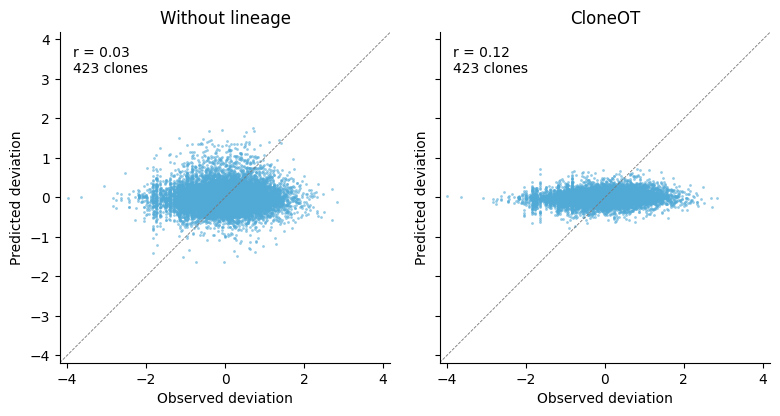

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)
test = tests['Seen clones']
for ax, (name, m) in zip(axes, [('Without lineage', no_lineage), ('CloneOT', model)]):
    cot.pl.clone_deviations(m.predict(test), model.observed(test), clone_key='clone', genes=genes, ax=ax)
    ax.set_title(name)
plt.tight_layout()

Each point is one gene of one held-out clone, namely the deviation of the clone mean from the average over clones.
A method that predicts the same response for every clone has no deviations.

## Saving and loading

A trained model is saved with its genes, VAE and cost, and predicts new cells after loading.

In [10]:
model.save('watermelon_day0_day3')
loaded = cot.CloneOTModel.load('watermelon_day0_day3')
np.allclose(loaded.predict(tests['Unseen clones']).X, model.predict(tests['Unseen clones']).X, atol=1e-5)

True